In [47]:
#Simple Linear Regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df= pd.read_csv("insurance.csv")

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
df.shape

(1338, 7)

In [6]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [8]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [9]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [12]:
missingValues = df.isnull().sum()
print(missingValues)

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [13]:
print(df.duplicated().sum())

1


In [14]:
df=df.drop_duplicates()

In [15]:
print(df.duplicated().sum())

0


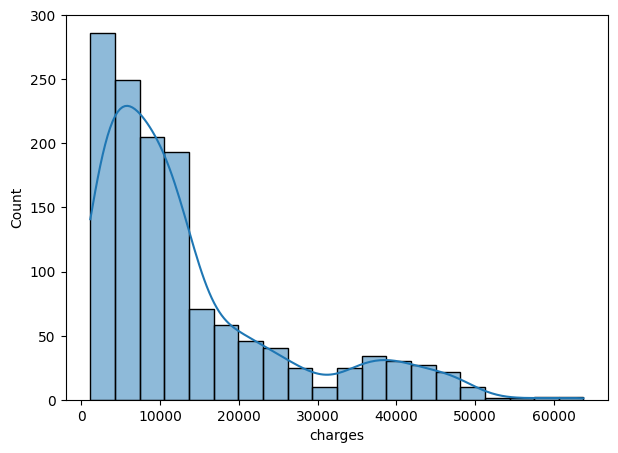

In [21]:
plt.figure(figsize=(7,5))
sns.histplot(
    data=df,
    x="charges",
    bins=20,
    kde=True
)
plt.show()

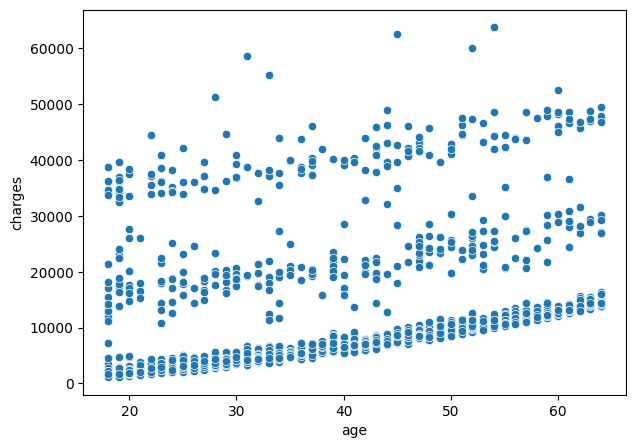

In [25]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df,
    x="age",
    y="charges",
)
plt.show()

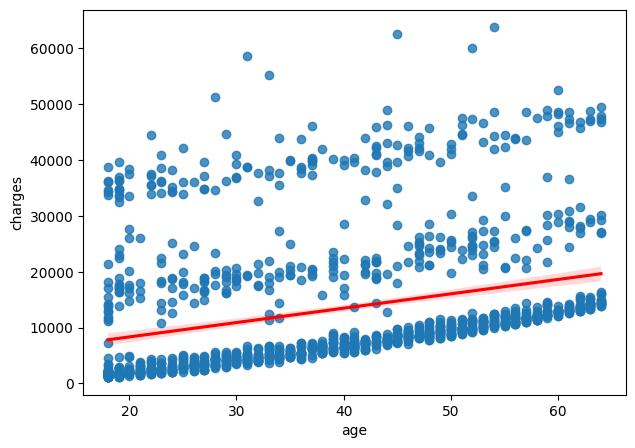

In [24]:
plt.figure(figsize=(7,5))
sns.regplot(
    data=df,
    x="age",
    y="charges",
    line_kws={"color":"red"}
)
plt.show()

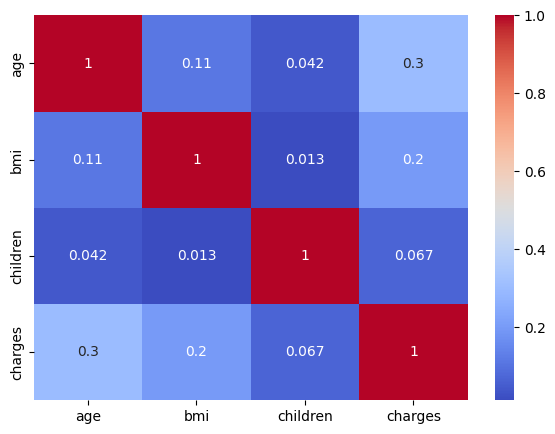

In [26]:
numeric_df =df.select_dtypes(include=["number"])
corr_matrix =numeric_df.corr()
plt.figure(figsize=(7,5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm"
)
plt.show()

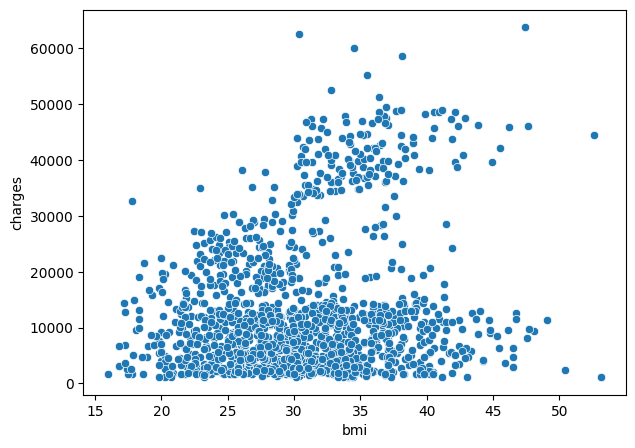

In [29]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df,
    x="bmi",
    y="charges"
)
plt.show()

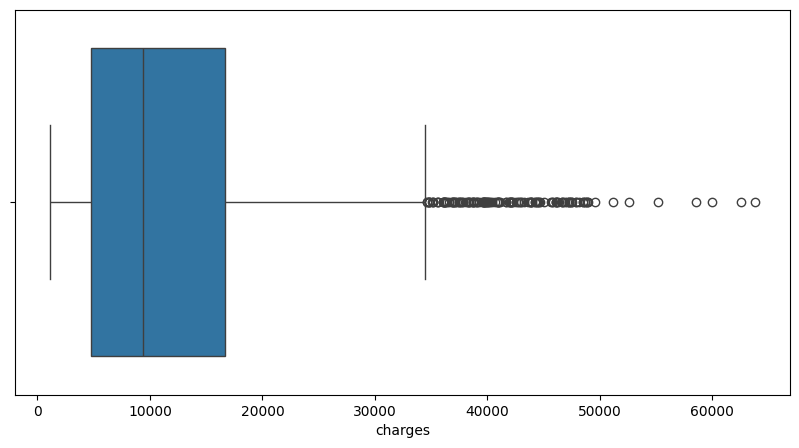

In [31]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x="charges")
plt.show()

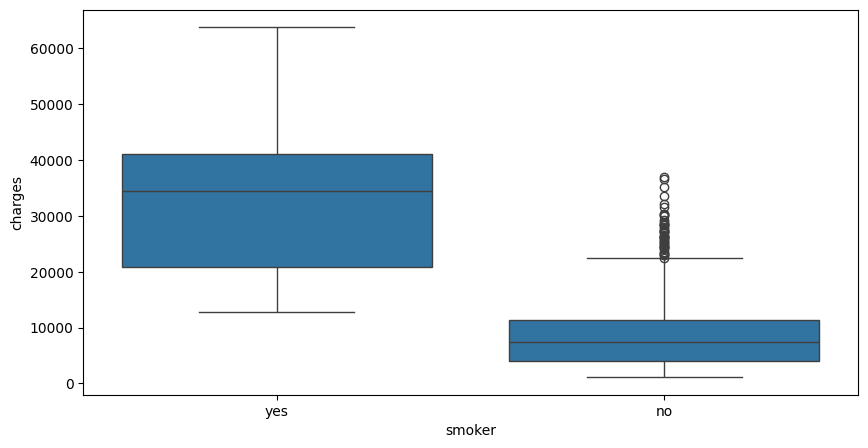

In [34]:
plt.figure(figsize=(10,5))
sns.boxplot(
    data=df,
    x="smoker",
    y="charges"
)
plt.show()

In [36]:
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, test_size=0.3, random_state=50)
val_df, test_df = train_test_split(test_df, test_size=0.5, random_state=50)
print("train:",train_df.shape)
print("Val:",val_df.shape)
print("Test:",test_df.shape)

train: (935, 7)
Val: (201, 7)
Test: (201, 7)


In [37]:
feature=["age"]
target="charges"
x_train=train_df[feature]
y_train=train_df[target]
x_val=val_df[feature]
y_val=val_df[target]
x_test=test_df[feature]
y_test=test_df[target]


In [39]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [40]:
print(model.coef_)
print(model.intercept_)

[256.21909911]
3228.626401771453


In [41]:
y_pred=model.predict(x_test)

In [42]:
comparison= pd.DataFrame({
    "Actual":y_test,
    "Predicted":y_pred}
)
comparison.head(10)

,Actual,Predicted
630,10085.84600,16808.238655
1003,21232.18226,15527.143159
284,9625.92000,16552.019556
248,1832.09400,8096.789285
49,38709.17600,12452.513970
573,31620.00106,19114.210547
1207,38415.47400,12452.513970
764,9095.06825,14758.485862
65,1743.21400,8096.789285
297,21978.67690,15270.924060


In [45]:
from sklearn.metrics import mean_squared_error,mean_absolute_error, r2_score
MAE = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error:", MAE)
MSE = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", MSE)
R2 = r2_score(y_test, y_pred)
print("R2 Score:", R2)


Mean Absolute Error: 9073.127151539433
Mean Squared Error: 133451827.6959309
R2 Score: 0.07780757716395026


In [46]:
#Multiple Linear Regression

In [49]:
features=["age","bmi","children","smoker","region","sex"]
target="charges"
x_train=pd.get_dummies(train_df[features],drop_first=True)
x_test=pd.get_dummies(test_df[features],drop_first=True)
x_val=pd.get_dummies(val_df[features],drop_first=True)
x_val=x_val.reindex(columns=x_train.columns,fill_value=0)
x_test=x_test.reindex(columns=x_train.columns,fill_value=0)
y_train=train_df[target]
y_test=test_df[target]
y_val=val_df[target]


In [50]:
from sklearn.linear_model import LinearRegression
multi_model=LinearRegression()
multi_model.fit(x_train,y_train)

LinearRegression()

In [51]:
print("Intercept:", multi_model.intercept_)
coefficients = pd.DataFrame({
    'Feature': x_train.columns,
    'Coefficient': multi_model.coef_
})
print(coefficients)

Intercept: -11010.110953121006
            Feature   Coefficient
0               age    250.388751
1               bmi    318.107778
2          children    393.066047
3        smoker_yes  23618.493562
4  region_northwest   -211.768504
5  region_southeast  -1125.116239
6  region_southwest   -661.459557
7          sex_male    -16.631391


In [52]:
y_pred_multi=multi_model.predict(x_test)

In [53]:
comparison= pd.DataFrame({
    "Actual":y_test,
    "Predicted":y_pred_multi}
)
comparison.head(10)

,Actual,Predicted
630,10085.84600,13459.158759
1003,21232.18226,9746.448397
284,9625.92000,11273.607238
248,1832.09400,110.702984
49,38709.17600,32071.089864
573,31620.00106,16632.510381
1207,38415.47400,32355.218592
764,9095.06825,9051.878268
65,1743.21400,2279.130550
297,21978.67690,31711.090984


In [54]:
from sklearn.metrics import mean_squared_error,mean_absolute_error, r2_score
multi_msa =mean_absolute_error(y_test, y_pred_multi)
print("Mean Absolute Error:", multi_msa)
multi_mse = mean_squared_error(y_test, y_pred_multi)
print("Mean Squared Error:", multi_mse)
multi_r2 = r2_score(y_test, y_pred_multi)
print("R2 Score:", multi_r2)

Mean Absolute Error: 3694.7400398600685
Mean Squared Error: 26814804.626863103
R2 Score: 0.8147016037647253


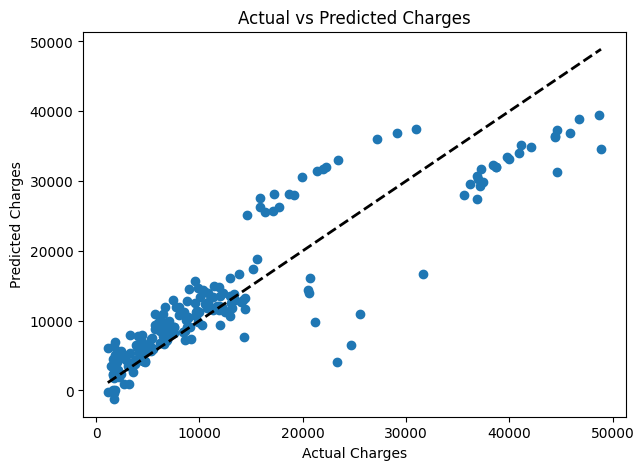

In [55]:
plt.figure(figsize=(7,5))
plt.scatter(y_test, y_pred_multi)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Charges")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

In [56]:
comparison= pd.DataFrame({
    "Model": ["Simple Linear Regression", "Multiple Linear Regression"],
    "MAE": [MAE, multi_msa],
    "MSE": [MSE, multi_mse],
    "R2": [R2, multi_r2]
})
print(comparison)


                        Model          MAE           MSE        R2
0    Simple Linear Regression  9073.127152  1.334518e+08  0.077808
1  Multiple Linear Regression  3694.740040  2.681480e+07  0.814702


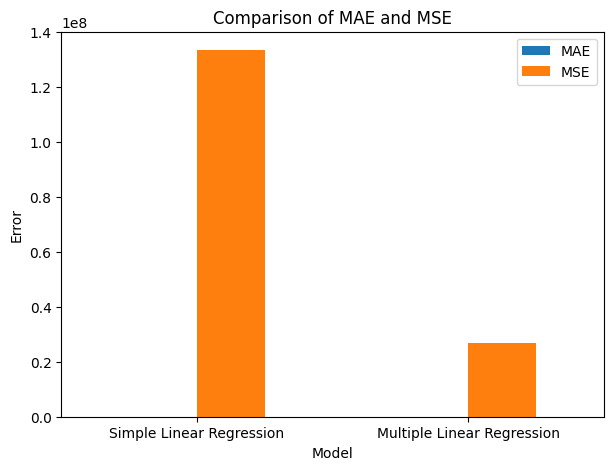

In [59]:
comparison.set_index("Model")[["MAE","MSE"]].plot(
    kind="bar",
    figsize=(7,5)
)
plt.title("Comparison of MAE and MSE")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.show()

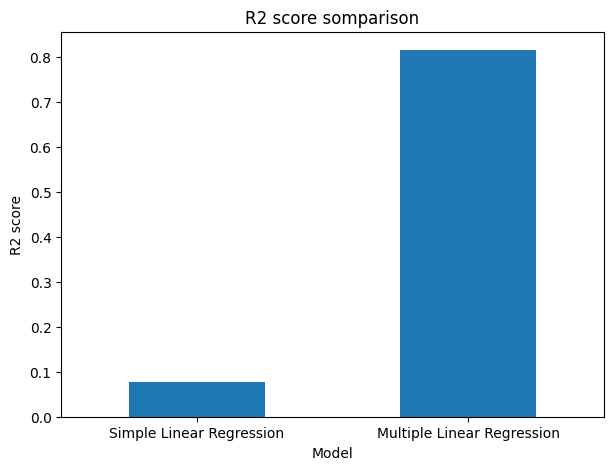

In [62]:
comparison.plot(
    x="Model",
    y="R2",
    kind="bar",
    figsize=(7,5),
    legend=False
)
plt.title("R2 score somparison")
plt.ylabel("R2 score")
plt.xticks(rotation=0)
plt.show()
